In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import SelfTrainingClassifier

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"

In [2]:
fraud = pd.read_csv(DATA / "credit_card_fraud_dataset.csv")
print(fraud.head())

feature_cols = [
    "amount", "transaction_hour", "foreign_transaction", "location_mismatch",
    "device_trust_score", "velocity_last_24h", "cardholder_age",
]
X = fraud[feature_cols]
y = fraud["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

forest = IsolationForest(n_estimators=300, contamination="auto", random_state=42, n_jobs=-1)
forest.fit(X_train)                                   # no labels passed
anomaly_score = -forest.decision_function(X_test)     # higher = more unusual

   transaction_id  amount  transaction_hour merchant_category  \
0               1   84.47                22       Electronics   
1               2  541.82                 3            Travel   
2               3  237.01                17           Grocery   
3               4  164.33                 4           Grocery   
4               5   30.53                15              Food   

   foreign_transaction  location_mismatch  device_trust_score  \
0                    0                  0                  66   
1                    1                  0                  87   
2                    0                  0                  49   
3                    0                  1                  72   
4                    0                  0                  79   

   velocity_last_24h  cardholder_age  is_fraud  
0                  3              40         0  
1                  1              64         0  
2                  1              61         0  
3                  3  

In [3]:
prevalence = y_test.mean()
ap = average_precision_score(y_test, anomaly_score)
print("fraud prevalence:", round(prevalence, 4))
print("ROC AUC:", round(roc_auc_score(y_test, anomaly_score), 4))
print("average precision:", round(ap, 4), " (", round(ap / prevalence, 1), "x prevalence)")

ranked = X_test.copy()
ranked["fraud_label"] = y_test.to_numpy()
ranked["anomaly_score"] = anomaly_score
ranked = ranked.sort_values("anomaly_score", ascending=False)
review_budget = 100

top_k_precision = ranked.head(review_budget)["fraud_label"].mean()
print(f"fraud found in the top {review_budget}: {top_k_precision:.0%}")
print(ranked[["fraud_label", "anomaly_score", "amount"]].head(10))

fraud prevalence: 0.015
ROC AUC: 0.9518
average precision: 0.2249  ( 15.0 x prevalence)
fraud found in the top 100: 20%
      fraud_label  anomaly_score  amount
6394            0       0.212892  840.89
5883            0       0.168657  978.56
1623            1       0.166446  569.02
522             0       0.165520  630.67
5536            1       0.163377   28.31
9073            0       0.158442  131.05
4642            0       0.155478  351.99
645             1       0.155063  398.17
7166            0       0.154388  353.58
7698            0       0.152780   75.88


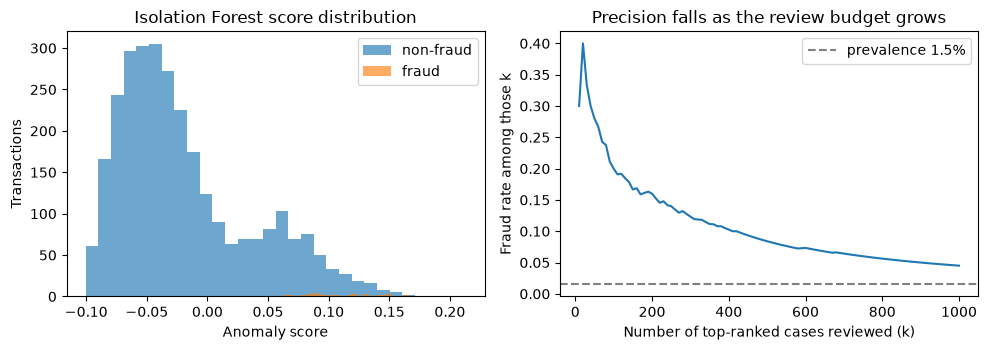

In [4]:
hits = ranked["fraud_label"].to_numpy()
k_values = np.arange(10, 1001, 10)
precision_at_k = [hits[:k].mean() for k in k_values]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(anomaly_score[y_test.to_numpy() == 0], bins=30, alpha=0.65, label="non-fraud")
axes[0].hist(anomaly_score[y_test.to_numpy() == 1], bins=30, alpha=0.65, label="fraud")
axes[0].set_xlabel("Anomaly score")
axes[0].set_ylabel("Transactions")
axes[0].set_title("Isolation Forest score distribution")
axes[0].legend()
axes[1].plot(k_values, precision_at_k)
axes[1].axhline(prevalence, linestyle="--", color="grey", label=f"prevalence {prevalence:.1%}")
axes[1].set_xlabel("Number of top-ranked cases reviewed (k)")
axes[1].set_ylabel("Fraud rate among those k")
axes[1].set_title("Precision falls as the review budget grows")
axes[1].legend()
plt.tight_layout()
plt.show()

Part B - Self training and active learning with few labels

In [5]:
rng = np.random.default_rng(42)

cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")
X_c = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int).to_numpy()

X_dev, Xc_test, y_dev, yc_test = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)
X_pool, X_val, y_pool, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=7, stratify=y_dev
)
X_pool = X_pool.reset_index(drop=True)
y_pool = np.asarray(y_pool)
print("pool:", len(X_pool), " validation:", len(X_val), " test:", len(Xc_test))

def make_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000)),
    ])

pool: 319  validation: 107  test: 143


In [6]:
y_partial = y_pool.copy()
y_partial[rng.random(len(y_partial)) < 0.70] = -1
print("labels kept:", int((y_partial != -1).sum()), "of", len(y_partial))

semi = Pipeline([
    ("scale", StandardScaler()),
    ("model", SelfTrainingClassifier(LogisticRegression(max_iter=2000), threshold=0.90)),
])
semi.fit(X_pool, y_partial)
print("self-training validation accuracy:",
      round(accuracy_score(y_val, semi.predict(X_val)), 3))

labels kept: 89 of 319
self-training validation accuracy: 0.963


In [7]:
class0 = np.where(y_pool == 0)[0]
class1 = np.where(y_pool == 1)[0]
initial = np.concatenate([rng.choice(class0, 20, replace=False),
                          rng.choice(class1, 20, replace=False)])
active_labeled = set(initial.tolist())
random_labeled = set(initial.tolist())
rng_random = np.random.default_rng(123)

query_batch, rounds = 15, 8
label_counts, active_scores, random_scores = [], [], []

for round_no in range(rounds):
    active_idx, random_idx = sorted(active_labeled), sorted(random_labeled)
    active = make_model().fit(X_pool.iloc[active_idx], y_pool[active_idx])
    random_model = make_model().fit(X_pool.iloc[random_idx], y_pool[random_idx])

    label_counts.append(len(active_labeled))
    active_scores.append(accuracy_score(y_val, active.predict(X_val)))
    random_scores.append(accuracy_score(y_val, random_model.predict(X_val)))
    print(f"round {round_no + 1}: labels={label_counts[-1]:3d} "
          f"uncertainty={active_scores[-1]:.3f} random={random_scores[-1]:.3f}")
    if round_no == rounds - 1:
        break

    unlabeled = np.array([i for i in range(len(X_pool)) if i not in active_labeled])
    uncertainty = np.abs(active.predict_proba(X_pool.iloc[unlabeled])[:, 1] - 0.5)
    active_labeled.update(unlabeled[np.argsort(uncertainty)[:query_batch]].tolist())

    unlabeled = np.array([i for i in range(len(X_pool)) if i not in random_labeled])
    random_labeled.update(rng_random.choice(unlabeled, query_batch, replace=False).tolist())

round 1: labels= 40 uncertainty=0.944 random=0.944
round 2: labels= 55 uncertainty=0.925 random=0.953
round 3: labels= 70 uncertainty=0.981 random=0.963
round 4: labels= 85 uncertainty=0.953 random=0.963
round 5: labels=100 uncertainty=0.953 random=0.953
round 6: labels=115 uncertainty=0.953 random=0.953
round 7: labels=130 uncertainty=0.953 random=0.963
round 8: labels=145 uncertainty=0.953 random=0.963


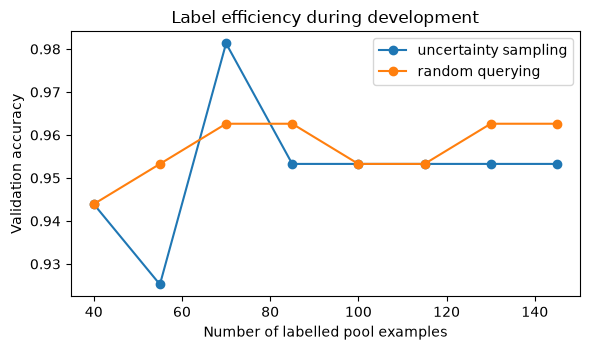

In [8]:
plt.figure(figsize=(6, 3.6))
plt.plot(label_counts, active_scores, marker="o", label="uncertainty sampling")
plt.plot(label_counts, random_scores, marker="o", label="random querying")
plt.xlabel("Number of labelled pool examples")
plt.ylabel("Validation accuracy")
plt.title("Label efficiency during development")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
active_idx, random_idx = sorted(active_labeled), sorted(random_labeled)
active_final = make_model().fit(X_pool.iloc[active_idx], y_pool[active_idx])
random_final = make_model().fit(X_pool.iloc[random_idx], y_pool[random_idx])
print("final test accuracy, uncertainty sampling:",
      round(accuracy_score(yc_test, active_final.predict(Xc_test)), 3))
print("final test accuracy, random querying:    ",
      round(accuracy_score(yc_test, random_final.predict(Xc_test)), 3))

final test accuracy, uncertainty sampling: 0.972
final test accuracy, random querying:     0.972


Activity 1 - compare fraud precision at 50 and 300

FRAUD PRECISION COMPARISON

Review budget: 50
Fraud detected: 14
Precision: 0.280
Precision (%): 28.0%

Review budget: 300
Fraud detected: 37
Precision: 0.123
Precision (%): 12.3%


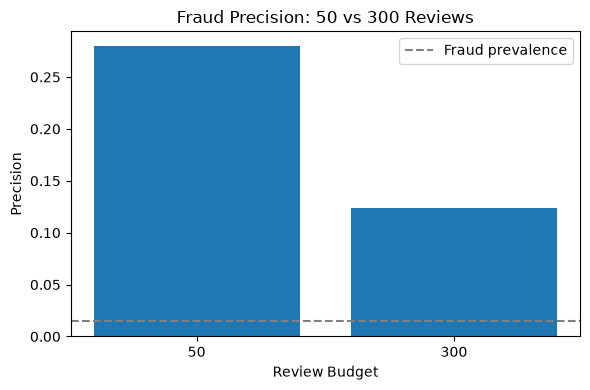

In [10]:
review_budgets = [50, 300]

print("FRAUD PRECISION COMPARISON")
print("=" * 45)

for budget in review_budgets:
    top_cases = ranked.head(budget)
    precision = top_cases["fraud_label"].mean()
    fraud_found = top_cases["fraud_label"].sum()

    print(f"\nReview budget: {budget}")
    print(f"Fraud detected: {int(fraud_found)}")
    print(f"Precision: {precision:.3f}")
    print(f"Precision (%): {precision:.1%}")

# Compare visually
precisions = [
    ranked.head(k)["fraud_label"].mean()
    for k in review_budgets
]

plt.figure(figsize=(6, 4))
plt.bar(
    [str(k) for k in review_budgets],
    precisions
)
plt.axhline(
    prevalence,
    linestyle="--",
    color="grey",
    label="Fraud prevalence"
)
plt.xlabel("Review Budget")
plt.ylabel("Precision")
plt.title("Fraud Precision: 50 vs 300 Reviews")
plt.legend()
plt.tight_layout()
plt.show()

Activity 2 - active learning with 10 labels per class

Round 1: Labels= 20 Uncertainty=0.935 Random=0.935
Round 2: Labels= 35 Uncertainty=0.944 Random=0.944
Round 3: Labels= 50 Uncertainty=0.963 Random=0.963
Round 4: Labels= 65 Uncertainty=0.953 Random=0.953
Round 5: Labels= 80 Uncertainty=0.953 Random=0.963
Round 6: Labels= 95 Uncertainty=0.953 Random=0.944
Round 7: Labels=110 Uncertainty=0.953 Random=0.953
Round 8: Labels=125 Uncertainty=0.953 Random=0.944


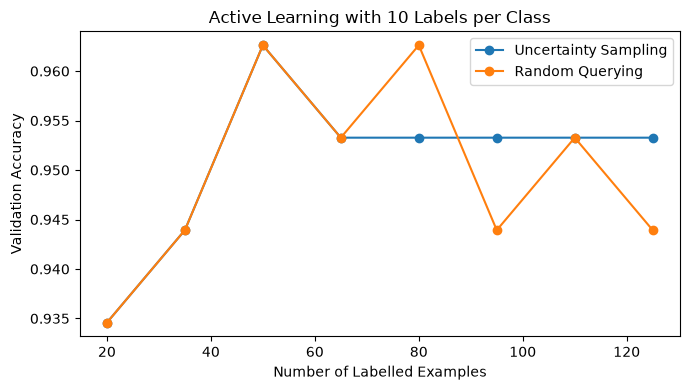


FINAL TEST RESULTS
Uncertainty Sampling: 0.972
Random Querying: 0.951


In [11]:
rng_active = np.random.default_rng(42)
rng_random = np.random.default_rng(123)

class0 = np.where(y_pool == 0)[0]
class1 = np.where(y_pool == 1)[0]

# Start with 10 labels per class (20 total)
initial = np.concatenate([
    rng_active.choice(class0, 10, replace=False),
    rng_active.choice(class1, 10, replace=False)
])

active_labeled = set(initial.tolist())
random_labeled = set(initial.tolist())

query_batch, rounds = 15, 8

label_counts = []
active_scores = []
random_scores = []

for round_no in range(rounds):

    active_idx = sorted(active_labeled)
    random_idx = sorted(random_labeled)

    active = make_model().fit(
        X_pool.iloc[active_idx],
        y_pool[active_idx]
    )

    random_model = make_model().fit(
        X_pool.iloc[random_idx],
        y_pool[random_idx]
    )

    label_counts.append(len(active_labeled))

    active_scores.append(
        accuracy_score(y_val, active.predict(X_val))
    )

    random_scores.append(
        accuracy_score(y_val, random_model.predict(X_val))
    )

    print(
        f"Round {round_no + 1}: "
        f"Labels={label_counts[-1]:3d} "
        f"Uncertainty={active_scores[-1]:.3f} "
        f"Random={random_scores[-1]:.3f}"
    )

    if round_no == rounds - 1:
        break

    # Uncertainty sampling
    unlabeled = np.array([
        i for i in range(len(X_pool))
        if i not in active_labeled
    ])

    uncertainty = np.abs(
        active.predict_proba(
            X_pool.iloc[unlabeled]
        )[:, 1] - 0.5
    )

    active_labeled.update(
        unlabeled[
            np.argsort(uncertainty)[:query_batch]
        ].tolist()
    )

    # Random sampling
    unlabeled = np.array([
        i for i in range(len(X_pool))
        if i not in random_labeled
    ])

    random_labeled.update(
        rng_random.choice(
            unlabeled,
            query_batch,
            replace=False
        ).tolist()
    )

# Visualize results
plt.figure(figsize=(7, 4))

plt.plot(
    label_counts,
    active_scores,
    marker="o",
    label="Uncertainty Sampling"
)

plt.plot(
    label_counts,
    random_scores,
    marker="o",
    label="Random Querying"
)

plt.xlabel("Number of Labelled Examples")
plt.ylabel("Validation Accuracy")
plt.title("Active Learning with 10 Labels per Class")
plt.legend()
plt.tight_layout()
plt.show()

# Final test comparison
active_idx = sorted(active_labeled)
random_idx = sorted(random_labeled)

active_final = make_model().fit(
    X_pool.iloc[active_idx],
    y_pool[active_idx]
)

random_final = make_model().fit(
    X_pool.iloc[random_idx],
    y_pool[random_idx]
)

print("\nFINAL TEST RESULTS")

print(
    "Uncertainty Sampling:",
    round(
        accuracy_score(
            yc_test,
            active_final.predict(Xc_test)
        ),
        3
    )
)

print(
    "Random Querying:",
    round(
        accuracy_score(
            yc_test,
            random_final.predict(Xc_test)
        ),
        3
    )
)